<a href="https://colab.research.google.com/github/sihamaness22-design/Eng-Frah-NLP/blob/main/Frah_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q pydicom albumentations

In [3]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import os
import tensorflow as tf
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import Sequence

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Activation, Dropout, Flatten, Dense, Input, Layer
from tensorflow.keras.layers import Embedding, LSTM, add, Concatenate, Reshape, concatenate, Bidirectional
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet201
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from textwrap import wrap
plt.rcParams['font.size'] = 12  # Set the font size for matplotlib plots
sns.set_style("dark")  # Set a dark style for seaborn plots
warnings.filterwarnings('ignore')  # Ignore warnings for cleaner output

In [9]:
import tensorflow as tf
import pandas as pd
import numpy as np

# Load MNIST directly and format it identically to Kaggle's digit-recognizer CSVs
(x_train, y_train), (x_test, _) = tf.keras.datasets.mnist.load_data()

train_pixels = x_train.reshape(-1, 784)
train = pd.DataFrame(train_pixels, columns=[f'pixel{i}' for i in range(784)])
train.insert(0, 'label', y_train)

test_pixels = x_test.reshape(-1, 784)
test = pd.DataFrame(test_pixels, columns=[f'pixel{i}' for i in range(784)])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Separate features and labels
y_train = train['label']
X_train = train.drop('label', axis=1)
X_test = test

print(f'Labels: {y_train.unique()}')
print(f'\nLabel distribution:')
print(y_train.value_counts().sort_index())

2026/11/16 18:25:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/16 18:25:24 INFO mlflow.store.db.utils: Updating database tables
2026/11/16 18:25:28 INFO mlflow.tracking.fluent: Experiment with name 'Dry_Bean_Classification' does not exist. Creating a new experiment.


Accuracy: 0.9203
Weighted F1-Score: 0.9203


In [11]:
# Separate features and labels
y_train = train['label']
X_train = train.drop('label', axis=1)
X_test = test

print(f'Labels: {y_train.unique()}')
print(f'\nLabel distribution:')
print(y_train.value_counts().sort_index())

Labels: [5 0 4 1 9 2 3 6 7 8]

Label distribution:
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


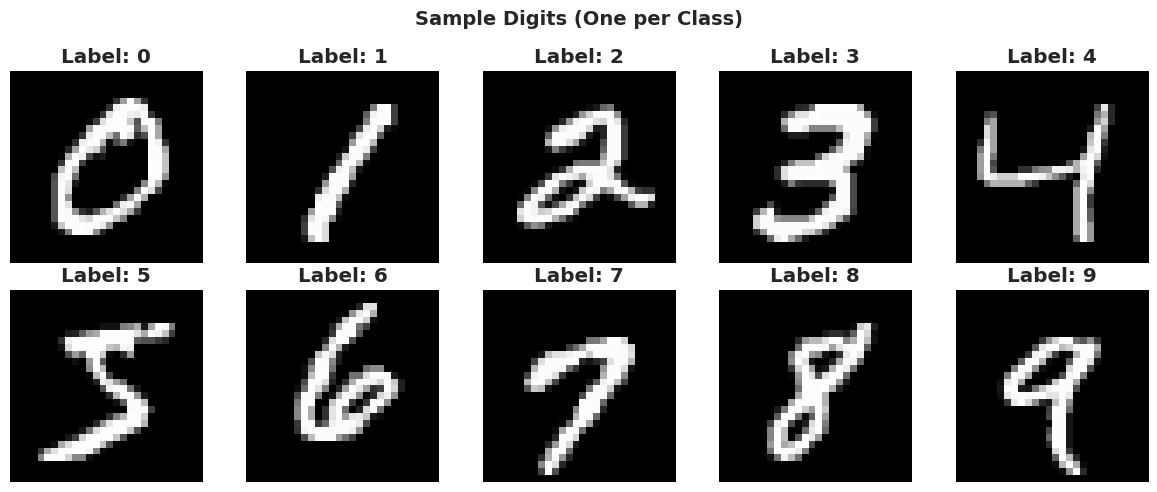

In [12]:
# Visualize some digits
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for i in range(10):
    idx = y_train[y_train == i].index[0]
    img = X_train.iloc[idx].values.reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f'Label: {i}', fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Sample Digits (One per Class)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

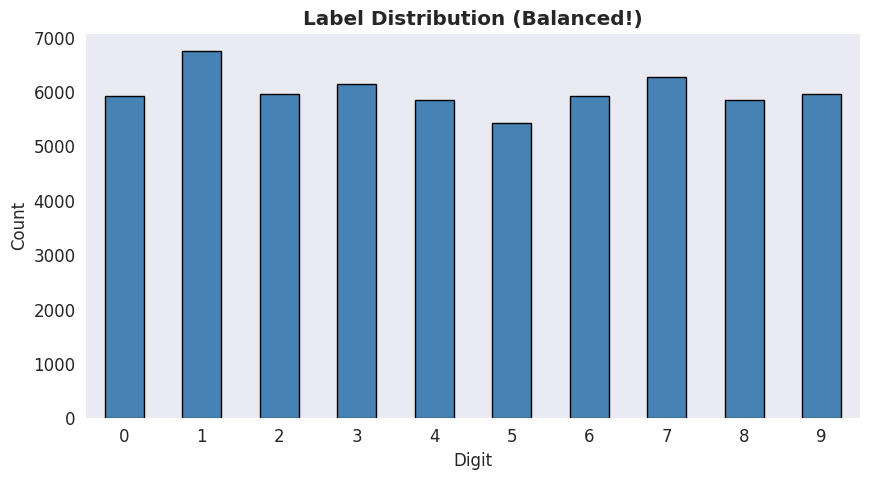

In [13]:
# Label distribution
plt.figure(figsize=(10, 5))
y_train.value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='black')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.title('Label Distribution (Balanced!)', fontweight='bold')
plt.xticks(rotation=0)
plt.show()

In [14]:
# Reshape for CNN: (samples, height, width, channels)
X_train_cnn = X_train.values.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.values.reshape(-1, 28, 28, 1)

# Normalize to 0-1
X_train_cnn = X_train_cnn / 255.0
X_test_cnn = X_test_cnn / 255.0

print(f'X_train shape: {X_train_cnn.shape}')
print(f'X_test shape: {X_test_cnn.shape}')
print(f'Pixel range: [{X_train_cnn.min()}, {X_train_cnn.max()}]')

X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)
Pixel range: [0.0, 1.0]


In [15]:
# One-hot encode labels
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, num_classes=10)
print(f'y_train shape: {y_train_cat.shape}')
print(f'Example (digit 3): {y_train_cat[y_train[y_train==3].index[0]]}')

y_train shape: (60000, 10)
Example (digit 3): [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

def build_cnn():
    model = Sequential([
        # First Conv Block
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)),
        BatchNormalization(),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # Second Conv Block
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # Dense Layers
        Flatten(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 872,426 (3.33 MB)

 Trainable params: 871,530 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

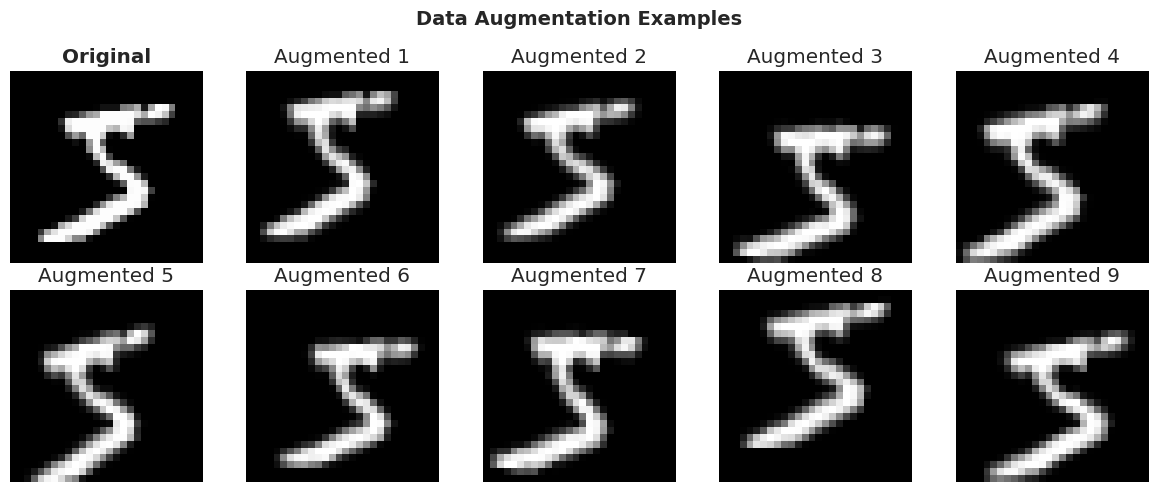

In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create augmented data generator
datagen = ImageDataGenerator(
    rotation_range=10,       # Rotate up to 10 degrees
    zoom_range=0.1,          # Zoom in/out up to 10%
    width_shift_range=0.1,   # Shift horizontally
    height_shift_range=0.1,  # Shift vertically
)

# Visualize augmented images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

img = X_train_cnn[0:1]  # Single image
axes[0].imshow(img[0, :, :, 0], cmap='gray')
axes[0].set_title('Original', fontweight='bold')
axes[0].axis('off')

for i, batch in enumerate(datagen.flow(img, batch_size=1)):
    if i >= 9:
        break
    axes[i+1].imshow(batch[0, :, :, 0], cmap='gray')
    axes[i+1].set_title(f'Augmented {i+1}')
    axes[i+1].axis('off')

plt.suptitle('Data Augmentation Examples', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from sklearn.model_selection import train_test_split

# Split for validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_cnn, y_train_cat, test_size=0.1, random_state=42, stratify=y_train
)

print(f'Training: {X_tr.shape[0]} samples')
print(f'Validation: {X_val.shape[0]} samples')

Training: 54000 samples
Validation: 6000 samples


In [20]:
# Callbacks
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)

# Train with augmentation
history = model.fit(
    datagen.flow(X_tr, y_tr, batch_size=64),
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, early_stop],
    verbose=1
)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 346s 410ms/step - accuracy: 0.9946 - loss: 0.0165 - val_accuracy: 0.9953 - val_loss: 0.0140 - learning_rate: 6.2500e-05
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 339s 401ms/step - accuracy: 0.9948 - loss: 0.0170 - val_accuracy: 0.9953 - val_loss: 0.0138 - learning_rate: 6.2500e-05
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 343s 407ms/step - accuracy: 0.9948 - loss: 0.0168 - val_accuracy: 0.9953 - val_loss: 0.0141 - learning_rate: 6.2500e-05
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 344s 407ms/step - accuracy: 0.9951 - loss: 0.0163 - val_accuracy: 0.9950 - val_loss: 0.0134 - learning_rate: 6.2500e-05
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 344s 408ms/step - accuracy: 0.9951 - loss: 0.0154 - val_accuracy: 0.9950 - val_loss: 0.0141 - learning_rate: 6.2500e-05
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 340s 403ms/step - accuracy: 0.9951 - loss: 0.0156 - val_accuracy: 0.9955 - val_loss: 0.0128 - learning_rate: 6.2500e-05
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 

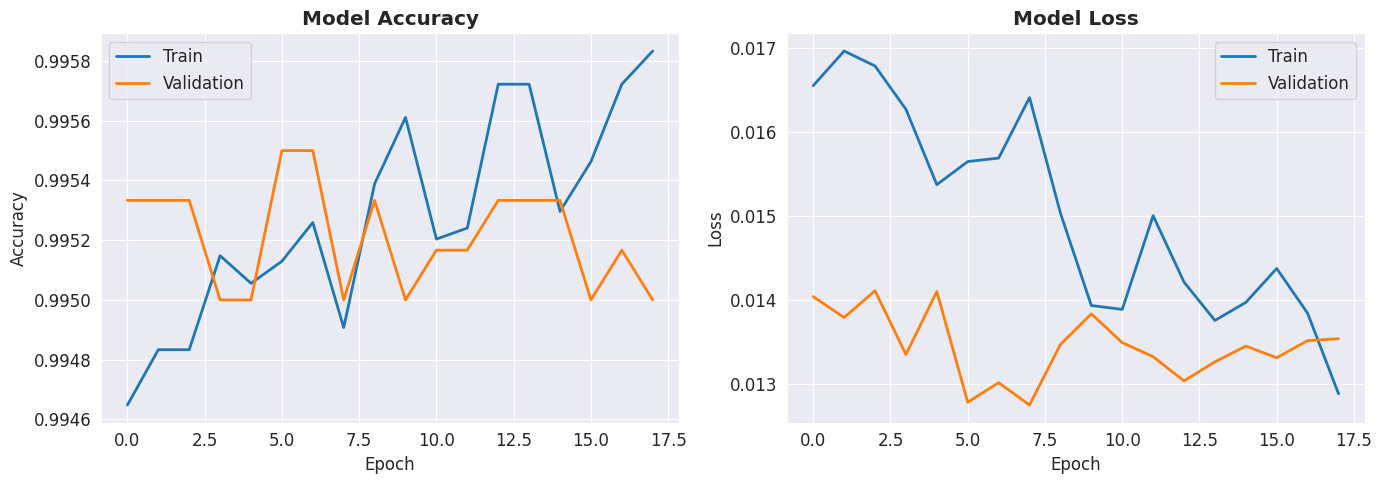


Final Validation Accuracy: 0.9950


In [21]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Model Accuracy', fontweight='bold')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'], label='Train', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Model Loss', fontweight='bold')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f'\nFinal Validation Accuracy: {history.history["val_accuracy"][-1]:.4f}')

188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step


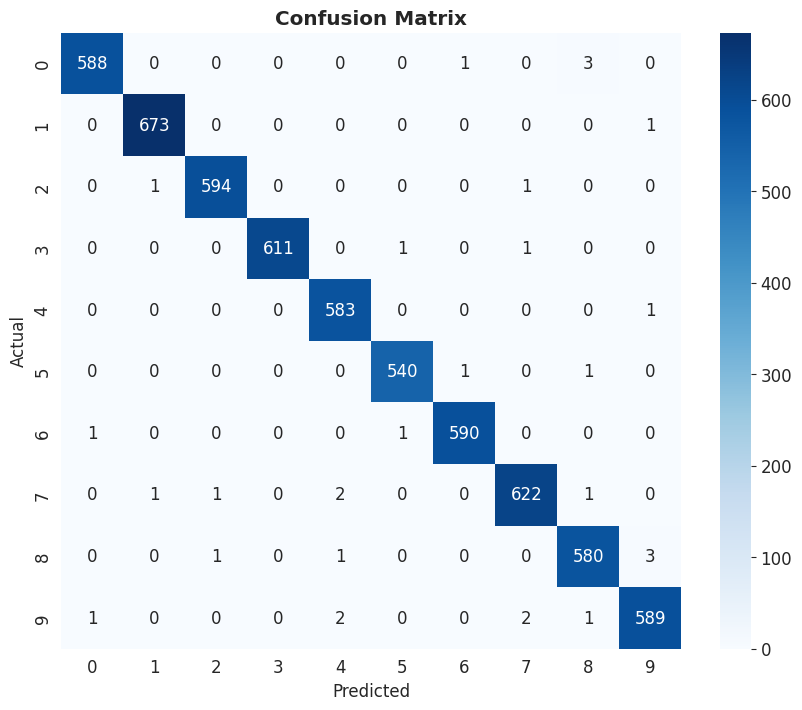

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       592
           1       1.00      1.00      1.00       674
           2       1.00      1.00      1.00       596
           3       1.00      1.00      1.00       613
           4       0.99      1.00      0.99       584
           5       1.00      1.00      1.00       542
           6       1.00      1.00      1.00       592
           7       0.99      0.99      0.99       627
           8       0.99      0.99      0.99       585
           9       0.99      0.99      0.99       595

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       1.00      0.99      1.00      6000



In [22]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict on validation set
y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_val, axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix', fontweight='bold')
plt.show()

print('Classification Report:')
print(classification_report(y_true, y_pred_classes))

Misclassified: 30 / 6000 (0.50%)


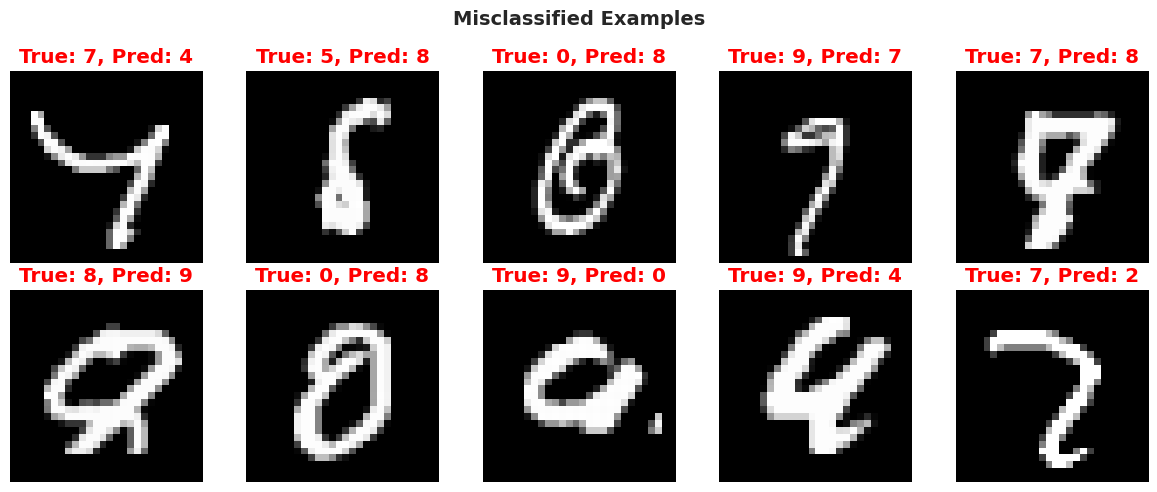

In [23]:
# Find misclassified
misclassified_idx = np.where(y_pred_classes != y_true)[0]

print(f'Misclassified: {len(misclassified_idx)} / {len(y_true)} ({len(misclassified_idx)/len(y_true)*100:.2f}%)')

# Show some misclassified examples
if len(misclassified_idx) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    axes = axes.flatten()

    for i, idx in enumerate(misclassified_idx[:10]):
        img = X_val[idx, :, :, 0]
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f'True: {y_true[idx]}, Pred: {y_pred_classes[idx]}',
                          fontweight='bold', color='red')
        axes[i].axis('off')

    plt.suptitle('Misclassified Examples', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [24]:
# Predict on test set
predictions = model.predict(X_test_cnn)
predicted_labels = np.argmax(predictions, axis=1)

submission = pd.DataFrame({
    'ImageId': range(1, len(predicted_labels) + 1),
    'Label': predicted_labels
})
submission.to_csv('submission.csv', index=False)

print('Submission saved!')
print(f'\nPrediction distribution:')
print(pd.Series(predicted_labels).value_counts().sort_index())
submission.head()

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step
Submission saved!

Prediction distribution:
0     980
1    1134
2    1029
3    1011
4     986
5     891
6     955
7    1033
8     974
9    1007
Name: count, dtype: int64


,ImageId,Label
0,1,7
1,2,2
2,3,1
3,4,0
4,5,4
